# Compare F.E. Walter reservoir operations

Start with the saved results from all three January 1–7, 2021 simulations. Then use **Run All** from your clone to reproduce the Rule-based baseline offline. The last section lets you make new Ollama runs for both LLM cases.

## Saved comparison

These are the first seven days of the archived F.E. Walter study trajectories. The two LLM cases used Ollama 0.40.6, `gemma4:12b` (Q4_K_M), seed 3, temperature 0.7, a 16,384-token context and 2,048 maximum output tokens. Each LLM made seven requests in this window. The MOSART-Urban rule made zero.

The archived model manifest SHA-256 is `4eb23ef187e2c5462566d6a1d3bbbc2f1346d0b4327cbb66d58fffbcc9b2b05c`. See the [study guide](../examples/fe_walter/README.md) to replay and score the complete 2021–2025 period or make new model runs.

In [1]:
from io import StringIO

import matplotlib.pyplot as plt
import pandas as pd

reference_csv = """
date,inflow_cms,rule_release,rule_storage,without_release,without_storage,with_release,with_storage
2021-01-01,10.670071982241376,0.0,5209609.5895126015,12.74258115,4158326.134315796,12.74258115,4158326.134315796
2021-01-02,8.77246894312245,0.0,5967550.906198381,12.74258115,3815308.4396415763,12.74258115,3815308.4396415763
2021-01-03,7.822622538884147,0.0,6643425.493557972,12.74258115,3390224.015641167,12.74258115,3390224.015641167
2021-01-04,7.334458992984942,0.0,7277122.750551871,12.74258115,2922962.261275066,12.74258115,2922962.261275066
2021-01-05,7.069910568828609,0.0,7887963.023698663,8.495054099999999,2799829.860181858,12.74258115,2432843.523061858
2021-01-06,6.913459323093393,0.0,8485285.909213932,8.495054099999999,2663180.071457127,6.912142352699999,2432957.3093038476
2021-01-07,6.809299974880447,0.0,9073609.427043602,8.495054099999999,2517530.9150467976,2.8316847,2776623.2690535183
"""
reference_daily = pd.read_csv(StringIO(reference_csv.strip()), parse_dates=["date"])
reference_cases = {
    "Rule-based": ("rule", 0),
    "Without operational knowledge": ("without", 7),
    "With operational knowledge": ("with", 7),
}
reference_runs = {}
reference_metrics = []
for name, (prefix, calls) in reference_cases.items():
    daily = reference_daily[["date", "inflow_cms", f"{prefix}_release", f"{prefix}_storage"]].rename(
        columns={f"{prefix}_release": "controlled_release_cms", f"{prefix}_storage": "storage_end_m3"}
    )
    reference_runs[name] = {"trajectory": daily}
    reference_metrics.append({
        "Case": name,
        "Mean controlled release (m³/s)": daily["controlled_release_cms"].mean(),
        "Jan 7 storage (million m³)": daily["storage_end_m3"].iloc[-1] / 1_000_000,
        "Ollama requests": calls,
    })
pd.DataFrame(reference_metrics).set_index("Case").round(3)

,Mean controlled release (m³/s),Jan 7 storage (million m³),Ollama requests
Case,,,
Rule-based,0.000,9.074,0
Without operational knowledge,10.922,2.518,7
With operational knowledge,10.494,2.777,7


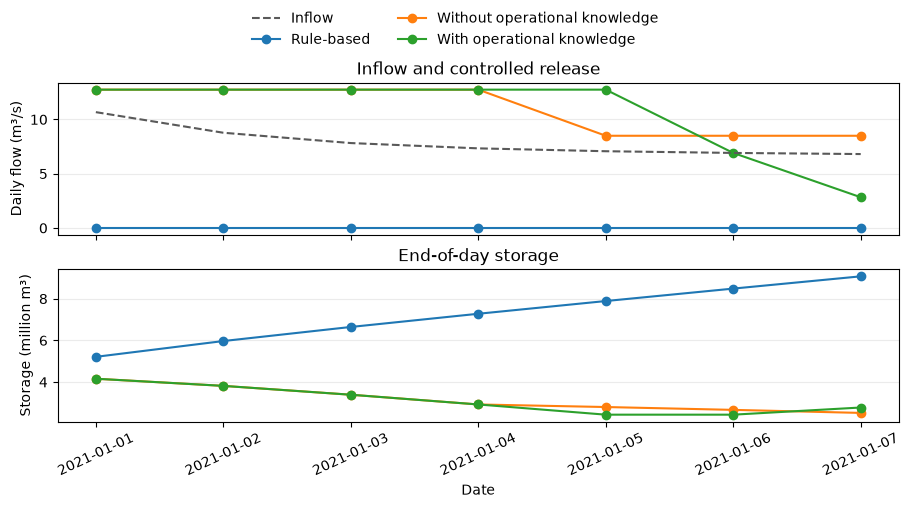

In [2]:
def plot_results(runs):
    figure, (flow_axis, storage_axis) = plt.subplots(2, 1, sharex=True, figsize=(9, 5), layout="constrained")
    inflow = runs["Rule-based"]["trajectory"]
    flow_axis.plot(inflow["date"], inflow["inflow_cms"], color="0.35", linestyle="--", label="Inflow", zorder=4)
    for name, run in runs.items():
        daily = run["trajectory"]
        flow_axis.plot(daily["date"], daily["controlled_release_cms"], marker="o", label=name)
        storage_axis.plot(daily["date"], daily["storage_end_m3"] / 1_000_000, marker="o", label=name)
    flow_axis.set(ylabel="Daily flow (m³/s)", title="Inflow and controlled release")
    storage_axis.set(ylabel="Storage (million m³)", xlabel="Date", title="End-of-day storage")
    figure.legend(*flow_axis.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
    for axis in (flow_axis, storage_axis):
        axis.grid(axis="y", alpha=0.25)
    storage_axis.tick_params(axis="x", labelrotation=25)
    return figure

preview_figure = plot_results(reference_runs)
plt.show()

Compare inflow with controlled release in the upper panel and end-of-day storage in the lower panel. The LLM trajectories reproduce the published study configurations and show the beginning of a five-year simulation.

## 1. Reproduce the Rule-based run

The MOSART-Urban rule uses the study inflow, rule-specific reservoir settings and 1996–2015 inflow statistics. Each execution writes a new verified run in a local temporary directory, whose path appears below. The daily table lists controlled release and spill separately.

In [ ]:
from pathlib import Path
from shutil import copytree
from tempfile import mkdtemp

import yaml

from llm_reservoir_agent.extensions import load_extension
from llm_reservoir_agent.verification import verify_run
from llm_reservoir_agent.workflow import load_settings, run_settings

root = Path.cwd()
if root.name == "tutorials":
    root = root.parent
example_dir = root / "examples" / "fe_walter"
if not (example_dir / "rule_based.yaml").is_file():
    raise FileNotFoundError("Open the notebook from the HydroReOpLLM checkout or its tutorials directory.")

config_paths = {
    "Rule-based": example_dir / "rule_based.yaml",
    "Without operational knowledge": example_dir / "seasonal_target.yaml",
    "With operational knowledge": example_dir / "dkp.yaml",
}


def run_case(name, *, allow_network=False):
    run_root = Path(mkdtemp(prefix="hydroreopllm-walter-"))
    case_copy = run_root / "examples" / "fe_walter"
    copytree(example_dir, case_copy)
    config_file = case_copy / config_paths[name].name
    if allow_network:
        config = yaml.safe_load(config_file.read_text(encoding="utf-8"))
        config["models"]["local"]["base_url"] = f"http://127.0.0.1:{OLLAMA_PORT}"
        config_file.write_text(yaml.safe_dump(config), encoding="utf-8")
    settings = load_settings(config_file)
    output = Path(settings.report["output"])
    print(f"{name} outputs: {output}")
    run_settings(settings, allow_network=allow_network)
    verification = verify_run(output, require_offline=not allow_network)
    trajectory = pd.read_csv(output / "reservoir_trajectory.csv", parse_dates=["date"])
    return {"trajectory": trajectory, "verification": verification, "output": output}

def verify_study_model(port):
    study, _ = load_extension("study/__init__.py", base_path=example_dir)
    study.verify_serving(f"http://127.0.0.1:{port}")

In [ ]:
baseline = run_case("Rule-based")
proof = baseline["verification"]
print(f"Verification {proof['status']} | {proof['days']} days | {proof['observed_network_calls']} network calls")
print(f"Maximum water balance residual: {proof['max_system_balance_residual_m3']:.3g} m³")

columns = {
    "date": "Date",
    "inflow_cms": "Inflow (m³/s)",
    "controlled_release_cms": "Controlled release (m³/s)",
    "spill_cms": "Spill (m³/s)",
    "storage_end_m3": "End storage (m³)",
}
daily_table = baseline["trajectory"][list(columns)].copy()
daily_table["date"] = daily_table["date"].dt.strftime("%Y-%m-%d")
daily_table.round(2).rename(columns=columns)

## 2. Inspect the study's prompts

The two LLM cases use the same seven dates, common physical inputs, and seasonal operating objectives. The study formatter inserts each day's starting pool and storage, inflow, and the previous two decisions and implemented releases into the user message. **With operational knowledge** also retrieves relevant sections from the complete local DKP. The first-day user messages are saved as readable files alongside the exact system prompts.

In [ ]:
check_results = {name: load_settings(path).report for name, path in config_paths.items()}
comparison = {}
for name in ("Without operational knowledge", "With operational knowledge"):
    config = yaml.safe_load(config_paths[name].read_text(encoding="utf-8"))
    method = config["agents"]["walter_operator"]["study_method"]
    comparison[name] = {
        "System prompt": f"prompts/{method}.system.txt",
        "First daily message": f"prompts/{method}.user.txt",
        "Operating guidance": "dkp.md" if method == "dkp" else "",
        "Planned decisions": check_results[name]["planned_llm_calls"],
    }

pd.DataFrame.from_dict(comparison, orient="index")

## 3. Optionally make new Ollama runs

Restore the pinned model using the [study guide](../examples/fe_walter/README.md) and start Ollama 0.40.6. Set `RUN_LLM` to `True` and select its local port before running the last cell. The verifier checks the model manifest and runtime before making a request. Each configuration permits up to 14 requests, including retries.

Use the [results guide](../docs/RESULTS_GUIDE.md) to inspect daily results and provider attempts. Use the study guide for the full 2021–2025 replay and evaluation.

In [ ]:
RUN_LLM = False
OLLAMA_PORT = 11434

In [ ]:
llm_runs = {}
if RUN_LLM:
    verify_study_model(OLLAMA_PORT)
    for name in comparison:
        llm_runs[name] = run_case(name, allow_network=True)
        verification = llm_runs[name]["verification"]
        print(f"Verification {verification['status']} | {verification['days']} days | {verification['observed_network_calls']} network calls")
    comparison_figure = plot_results({"Rule-based": baseline, **llm_runs})
    plt.show()
else:
    print("Run All completed the offline baseline. Enable RUN_LLM above to compare the two Ollama runs.")